# F02 保存水分子结果复核

**课程修订P1-1；核心0.1.0。跟随操作：基础；独立解释：进阶。**

先修：普通化学、分子结构；解释还需RHF、基组、线性代数及非正交AO度量。分析对象为固定教学几何、中性单重态RHF/6-31G(d)的一次历史保存结果；18个AO、10个电子。

本课只做保存数据后处理，**新量子计算调用0次，新RHF继续未验收**。不启动Docker、WSL或PySCF，不做几何优化，不把教学几何称为实验结构。

阅读版展示真实数值、表格与静态图。GitHub预览不执行Python。交互运行请按README准备依赖；原代码的Colab准备单元默认关闭；独立Colab适配版已完成限定范围验收，具体边界见页首。

原文件中的执行ID、镜像/提交哈希与SCF调用记录属于历史来源，不代表本课执行了新的SCF。原记录资格不由本次课程重新颁发。

## 当前课程状态（2026-10-19）

五课已完成真实Colab默认/修改参数共10轮运行、私有依赖安装、手工参数修改、结果重载及Drive另存副本。五份原生下载的Notebook已核验；其内嵌结果ZIP均与云端结果逐字节一致。单独点击ZIP链接下载仍未验；新RHF仍未验收（NOT_EXECUTED）。

本次仅更新公开导航和状态文字，不改变科学代码、样本、内置wheel及运行器。保存的科学输出和Colab内置原课中的旧状态文字属于历史快照，以本页说明及docs/STATUS.md为准；FAIL、DIAGNOSTIC及NOT_ASSESSED边界不变。

GitHub只显示静态内容；交互计算使用独立Colab适配。公开页面/固定ref入口首次同步后单独核对；Binder、其它账号/环境、试学与独立解释能力未验收。

[课程首页](../README.md) · [交互运行说明](../docs/RUNNING.md) · [完成与未验收范围](../docs/STATUS.md)

## 学习与验收范围

五课已完成真实Colab默认/修改参数共10轮运行、私有依赖安装、手工参数修改、结果重载及Drive另存副本。五份原生下载的Notebook已核验；其内嵌结果ZIP均与云端结果逐字节一致。单独点击ZIP链接下载仍未验；新RHF仍未验收（NOT_EXECUTED）。

本次仅更新公开导航和状态文字，不改变科学代码、样本、内置wheel及运行器。保存的科学输出和Colab内置原课中的旧状态文字属于历史快照，以本页说明及docs/STATUS.md为准；FAIL、DIAGNOSTIC及NOT_ASSESSED边界不变。

GitHub只显示静态内容；交互计算使用独立Colab适配。公开页面/固定ref入口首次同步后单独核对；Binder、其它账号/环境、试学与独立解释能力未验收。

[五课入口](../README.md) · [本课Colab适配](../colab/F02-colab.ipynb)

In [1]:
PREPARE_COLAB = False
if PREPARE_COLAB:
    import hashlib, json, os, subprocess, sys, uuid, zipfile
    from pathlib import Path, PurePosixPath
    from google.colab import files
    if sys.version_info < (3,12):
        raise RuntimeError("本课核心要求Python 3.12或更新版本；当前云端环境未验收。")
    uploaded = files.upload()
    if len(uploaded) != 1:
        raise ValueError("请选择本课一个ZIP；不要上传私有资料。")
    filename = next(iter(uploaded))
    target = Path("f02-cloud-" + uuid.uuid4().hex)
    target.mkdir(exist_ok=False)
    with zipfile.ZipFile(filename) as z:
        for item in z.infolist():
            name = PurePosixPath(item.filename)
            if name.is_absolute() or ".." in name.parts or ":" in item.filename or "\\" in item.filename or (item.external_attr >> 16) & 0o170000 == 0o120000:
                raise ValueError("ZIP包含非法路径或链接")
        if sum(i.file_size for i in z.infolist()) > 32*1024*1024:
            raise ValueError("ZIP解包内容超出课程预算")
        z.extractall(target)
    record = json.loads((target / "lesson-manifest.json").read_text("utf-8"))
    for item in record["inputs"] + [record["wheel"]]:
        rel = PurePosixPath(item["file"])
        if rel.is_absolute() or ".." in rel.parts or ":" in item["file"] or "\\" in item["file"]:
            raise ValueError("课程清单路径非法")
        if hashlib.sha256((target / item["file"]).read_bytes()).hexdigest() != item["sha256"]:
            raise ValueError("课程文件哈希不符")
    subprocess.check_call([sys.executable,"-m","pip","install","-r","requirements.txt"], cwd=target)
    os.chdir(target)
    print("课程文件已准备；必要时按Colab提示重启后重新准备。云端验收尚未执行。")
else:
    print("云端安装关闭；本地按导学准备依赖后顺序运行。")


云端安装关闭；本地按导学准备依赖后顺序运行。


## 1. 输入完整性、单位与AO顺序

核对review请求、result、arrays、molecule.xyz、request和origin以及oracle的哈希。原始AO排序必须在所有矩阵行列及AO标签中一致，不凭18×18形状猜测对应关系。

样本只含数值数组，使用allow_pickle=False读取。每次运行另建输出目录；来源文件与样本保持只读。公开课程保留必要的历史执行ID和来源哈希，但不展示本机路径、PID或登录信息。

In [2]:
import copy, hashlib, io, json, uuid
from decimal import Decimal
from pathlib import Path
import numpy as np
from IPython.display import display, HTML, Image
from ai4orgchem_data_processing.analysis import analyze, run_analysis

roots=[p for base in (Path.cwd(),*Path.cwd().parents)
       for p in (base,base/"learning/water_review")
       if (p/"lesson-manifest.json").is_file()
       and json.loads((p/"lesson-manifest.json").read_text("utf-8")).get("lesson")=="F02"]
if not roots:raise FileNotFoundError("请从完整课程目录或项目内启动，先查看导学。")
lesson_root=roots[0];manifest=json.loads((lesson_root/"lesson-manifest.json").read_text("utf-8"))
for item in manifest["inputs"]:
    assert hashlib.sha256((lesson_root/item["file"]).read_bytes()).hexdigest()==item["sha256"]
samples=lesson_root/"samples";task=json.loads((samples/"review.json").read_text("utf-8"))
workspace=lesson_root/"outputs"/("study-"+uuid.uuid4().hex);workspace.mkdir(parents=True,exist_ok=False)
def raw(t):return json.dumps(t,ensure_ascii=False,allow_nan=False).encode("utf-8")
print("历史保存数据；来源文件哈希PASS；同一原始AO顺序；本次新量子计算0次。")

历史保存数据；来源文件哈希PASS；同一原始AO顺序；本次新量子计算0次。


## 2. 非正交AO密度与电子数

本课D是**自旋求和、原AO顺序的非正交AO密度矩阵**，S为同一AO基的重叠矩阵。

$$N=\mathrm{Tr}(DS),\qquad N=10$$

不能直接把Tr(D)当电子数。先检查矩阵对称性、S正定和条件数，再解释依赖该度量的结果。矩阵迹本身无量纲；AO密度不是实验实空间密度。

In [3]:
report=run_analysis(raw(task),samples,workspace/"main")
assert report.exit_code==0 and report.analysis_status=="PASS"
r=report.results
assert abs(r["electron_number"]-10)<=1e-8
assert abs(r["trace_density_without_overlap"]-10)>1e-3
assert r["density_relative_frobenius"]<=1e-9 and r["occupied_orthonormality_frobenius"]<=1e-8
assert report.scientific_qualification=="NOT_ASSESSED" and report.new_scientific_calls==0
with np.load(samples/"arrays.npz",allow_pickle=False) as a:
    S,D,C,occ,h,V=[a[k] for k in ["overlap","density","canonical_coefficients","occupations","hcore","veff"]]
    assert all(a[k].dtype.kind in "fiu" for k in a.files)
eigenvalues=np.linalg.eigvalsh(S)
assert eigenvalues[0]>=1e-10 and eigenvalues[-1]/eigenvalues[0]<=1e10
assert abs(float(np.trace(D@S))-10)<=1e-8
print(f"Tr(DS)={r['electron_number']:.12g}；Tr(D)={r['trace_density_without_overlap']:.12g}（后者不是本例电子数）")
print(f"S最小本征值={eigenvalues[0]:.6g}；条件数={eigenvalues[-1]/eigenvalues[0]:.6g}")

Tr(DS)=10；Tr(D)=6.69226156488（后者不是本例电子数）
S最小本征值=0.062546；条件数=55.2664


## 3. 密度重建与轨道表示

$$D_C=C\,\mathrm{diag}(n)C^T,\qquad C_{occ}^TSC_{occ}=I$$

本例5个占据轨道各占据2电子，其余13个占据为0。轨道列的整体符号可变，不能要求轨道系数逐元素相同来判断两种表示一致。密度、占据正交及相应能量不变量才是这里核对的对象。

下列重建是对同一次历史数组的独立算术交叉核对，不是另一种电子结构引擎验证。

In [4]:
assert C.shape==D.shape==S.shape==(18,18)
assert list(occ).count(2)==5 and list(occ).count(0)==13
rebuilt=(C*occ)@C.T
np.testing.assert_allclose(rebuilt,D,atol=1e-12,rtol=1e-12)
occupied=C[:,occ>0]
assert np.linalg.norm(occupied.T@S@occupied-np.eye(5))<=1e-8
signed=C.copy();signed[:,0]*=-1
np.testing.assert_allclose((signed*occ)@signed.T,D,atol=1e-12,rtol=1e-12)
print(f"密度相对Frobenius残差={r['density_relative_frobenius']:.6g}；占据正交残差={r['occupied_orthonormality_frobenius']:.6g}")
print("翻转一列轨道符号：占据密度不变；不将轨道系数逐元素差异当作失败。")

密度相对Frobenius残差=0；占据正交残差=2.23757e-15
翻转一列轨道符号：占据密度不变；不将轨道系数逐元素差异当作失败。


## 4. 能量重建与解释边界

$$E=\mathrm{Tr}(Dh)+\frac12\mathrm{Tr}(DV)+E_{nuc}$$

使用保存的hcore、veff和核排斥项，能量单位Eh。电子能与含核排斥总能要区分；核排斥为正不表示总能必须为正。总能绝对值不能脱离方法、基组与体系直接比较。

能量重建和闭合采用atol=1e-9 Eh、rtol=0。电子数绝对误差<=1e-8；密度相对Frobenius<=1e-9；占据正交Frobenius<=1e-8，均来自冻结合同，不是自动放宽后的门槛。

In [5]:
one=float(np.trace(D@h));two=float(.5*np.trace(D@V));nuclear=r["nuclear_repulsion_hartree"]
total=one+two+nuclear
assert abs(total-(-76.00909910859735))<=1e-9
assert abs(total-r["reconstructed_total_hartree"])<=1e-9
decimal_total=Decimal("-123.05295724302984")+Decimal("37.85559971668637")+Decimal("9.188258417746113")
assert abs(decimal_total-Decimal("-76.00909910859735"))<=Decimal("1e-9")
display(HTML("<table><tr><th>量</th><th>值 (Eh)</th></tr>"+"".join(f"<tr><td>{name}</td><td>{value:.14f}</td></tr>" for name,value in [("One electron",one),("Two electron",two),("Nuclear repulsion",nuclear),("Reconstructed total",total)])+"</table>"))
print("总能重建与十进制账本PASS；科学资格仍为NOT_ASSESSED。")

量,值 (Eh)
One electron,-123.05295724302985
Two electron,37.85559971668636
Nuclear repulsion,9.18825841774611
Reconstructed total,-76.00909910859738


总能重建与十进制账本PASS；科学资格仍为NOT_ASSESSED。


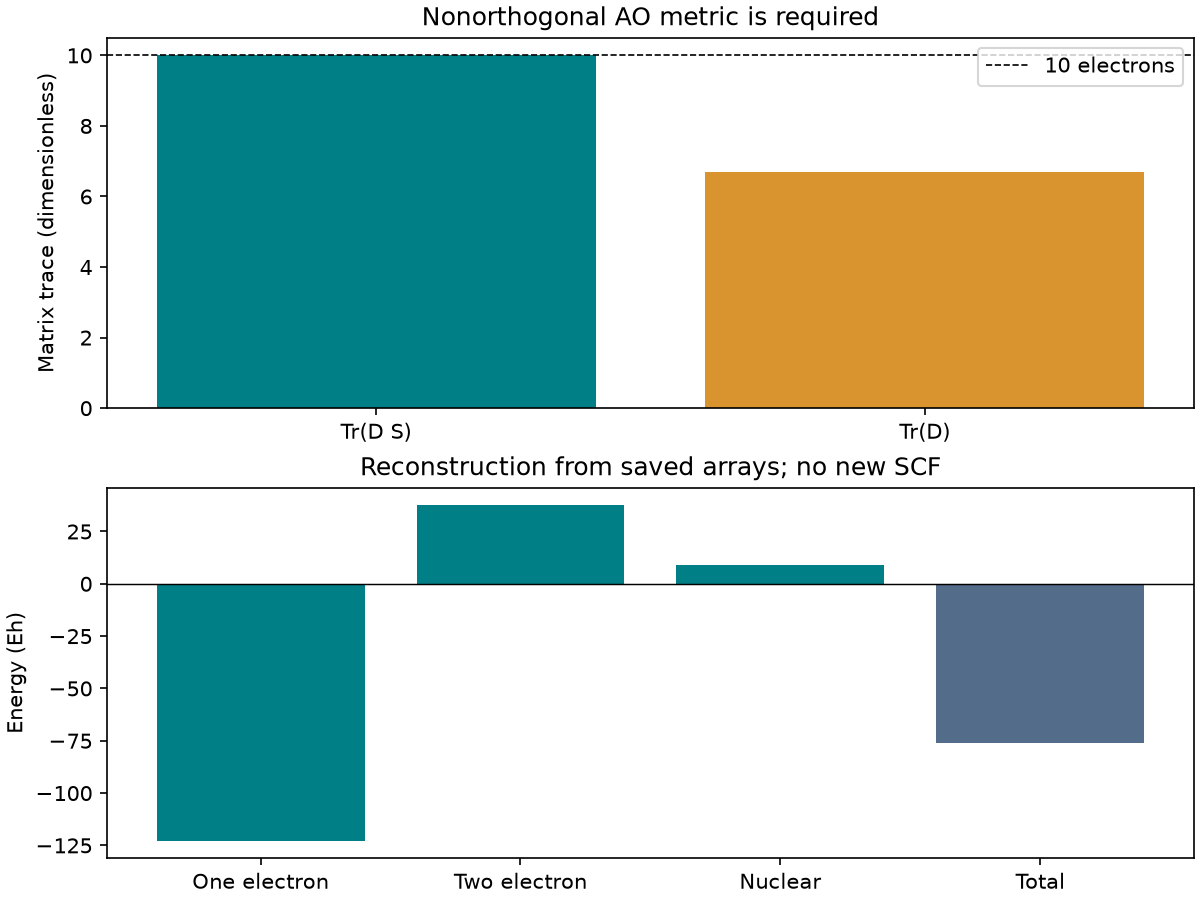

In [6]:
from matplotlib.figure import Figure
from matplotlib.backends.backend_agg import FigureCanvasAgg
fig=Figure(figsize=(8,6),layout="constrained");FigureCanvasAgg(fig)
top,bottom=fig.subplots(2,1)
top.bar(["Tr(D S)","Tr(D)"],[r["electron_number"],r["trace_density_without_overlap"]],color=["#007f86","#d99430"])
top.axhline(10,color="black",linestyle="--",linewidth=.8,label="10 electrons")
top.set_ylabel("Matrix trace (dimensionless)");top.legend();top.set_title("Nonorthogonal AO metric is required")
bottom.bar(["One electron","Two electron","Nuclear","Total"],[one,two,nuclear,total],color=["#007f86","#007f86","#007f86","#526c8a"])
bottom.axhline(0,color="black",linewidth=.7);bottom.set_ylabel("Energy (Eh)")
bottom.set_title("Reconstruction from saved arrays; no new SCF")
fig.savefig(workspace/"saved-water-review.png",dpi=150)
display(Image(filename=str(workspace/"saved-water-review.png")))

上图比较两种矩阵迹，只有Tr(DS)对应本课电子数；Tr(D)的偏离不自动说明原密度错误。下图是保存数组的能量分项，不是势能面、轨道能谱或新的RHF计算结果。

## 5. 可选全MO诊断：不是资格升级

请求full_mo_eigen_residual_diagnostic需要额外Fock与轨道能数组。保存样本具备这些数组，但该检查仅DIAGNOSTIC，没有冻结验收阈值。其数值可展示，不能称完整虚轨道、波函数稳定性或物理基态认证。

In [7]:
diagnostic_task=copy.deepcopy(task)
diagnostic_task["parameters"]["requested_checks"]=["full_mo_eigen_residual_diagnostic"]
diagnostic=run_analysis(raw(diagnostic_task),samples,workspace/"diagnostic")
check=next(c for c in diagnostic.checks if c.name=="full_mo_eigen_residual_diagnostic")
assert check.status=="DIAGNOSTIC" and diagnostic.scientific_qualification=="NOT_ASSESSED"
assert diagnostic.new_scientific_calls==0
print(f"全MO残差={check.actual:.6g} Eh；状态DIAGNOSTIC；不据此发放科学资格。")

全MO残差=5.40604e-09 Eh；状态DIAGNOSTIC；不据此发放科学资格。


## 6. 反例副本与输入拒绝

下面只修改新建教学副本：缺S应拒绝，反转AO标签应判不可比较，来源字节变了但哈希不变应拒绝。将S改成-I时矩阵仍对称却不是正定度量，科学检查FAIL，依赖的电子数等检查NOT_EXECUTED。

副本哈希只证明字节一致，不能把教学修改认证成新后端结果。副本沿用历史执行ID仅用于追溯关系；variant-map记录原哈希和变更，不重新颁发原资格。

In [8]:
def variant(label,change_arrays=None,change_result=None):
    directory=workspace/"variants"/label;directory.mkdir(parents=True,exist_ok=False)
    changed=copy.deepcopy(task)
    for ref in changed["data"].values():(directory/ref["file"]).write_bytes((samples/ref["file"]).read_bytes())
    record=json.loads((directory/"result.json").read_text("utf-8"))
    if change_arrays:
        with np.load(directory/"arrays.npz",allow_pickle=False) as a:arrays={k:a[k] for k in a.files}
        change_arrays(arrays);buffer=io.BytesIO();np.savez(buffer,**arrays)
        (directory/"arrays.npz").write_bytes(buffer.getvalue())
        changed["data"]["arrays"]["sha256"]=hashlib.sha256(buffer.getvalue()).hexdigest()
        record["array_artifact_sha256"]=changed["data"]["arrays"]["sha256"]
    if change_result:change_result(record)
    result_bytes=json.dumps(record,ensure_ascii=False).encode("utf-8");(directory/"result.json").write_bytes(result_bytes)
    changed["data"]["result"]["sha256"]=hashlib.sha256(result_bytes).hexdigest()
    origin=json.loads((directory/"origin.json").read_text("utf-8"));origin["record_sha256"]=changed["data"]["result"]["sha256"]
    origin_bytes=json.dumps(origin).encode("utf-8");(directory/"origin.json").write_bytes(origin_bytes)
    changed["data"]["origin"]["sha256"]=hashlib.sha256(origin_bytes).hexdigest()
    changed["provenance"]["description"]="DERIVED_TEACHING_COPY: "+label+"; not a new Runtime execution or qualification"
    mapping={"kind":"DERIVED_TEACHING_COPY","change":label,"new_quantum_calls":0,
             "original_arrays_sha256":task["data"]["arrays"]["sha256"],"derived_arrays_sha256":changed["data"]["arrays"]["sha256"],
             "original_record_sha256":task["data"]["result"]["sha256"],"derived_record_sha256":changed["data"]["result"]["sha256"]}
    (directory/"variant-map.json").write_text(json.dumps(mapping,indent=2),encoding="utf-8")
    return changed,directory
rejections=[]
missing,folder=variant("missing-overlap",change_arrays=lambda a:a.pop("overlap"))
refused=analyze(raw(missing),folder)
assert refused.exit_code==2 and refused.errors[0]["code"]=="MISSING_ARRAY"
rejections.append("MISSING_ARRAY")
wrong,folder=variant("wrong-ao-order",change_result=lambda r:r.update(ao_labels=list(reversed(r["ao_labels"]))))
refused=analyze(raw(wrong),folder)
assert refused.exit_code==3 and refused.errors[0]["code"]=="INCOMPATIBLE_COMPARISON"
rejections.append("INCOMPATIBLE_COMPARISON")
stale,folder=variant("stale-hash")
(folder/"result.json").write_bytes((folder/"result.json").read_bytes()+b" ")
refused=analyze(raw(stale),folder)
assert refused.execution_status=="REJECTED" and refused.errors[0]["code"]=="HASH_MISMATCH"
rejections.append("HASH_MISMATCH")
bad_task,bad_inputs=variant("nonpositive-overlap",change_arrays=lambda a:a.update(overlap=-np.eye(18)))
bad_metric=run_analysis(raw(bad_task),bad_inputs,workspace/"bad-metric")
assert bad_metric.execution_status=="SUCCEEDED" and bad_metric.analysis_status=="FAIL" and bad_metric.exit_code==4
assert next(c for c in bad_metric.checks if c.name=="electron_number").status=="NOT_EXECUTED"
assert "electron_number" not in bad_metric.results
print("三个拒绝例按预期；坏S：FAIL，依赖检查未执行，不输出虚构电子数。")

三个拒绝例按预期；坏S：FAIL，依赖检查未执行，不输出虚构电子数。


## 7. 交互练习：翻转一个占据轨道符号

将FLIP_OCCUPIED_ORBITAL由False改为True并从头运行。C第一列会变号；密度、电子数及总能应保持不变。与直接比较轨道系数不同，这里核对合同声明的不变量。

教学副本不修改samples，修改后会重新记录字节哈希及关系映射；这些哈希不代表新科学计算资格。

In [9]:
FLIP_OCCUPIED_ORBITAL = False
assert isinstance(FLIP_OCCUPIED_ORBITAL,bool)
def flip(a):a["canonical_coefficients"][:,0]*=-1
explore_task,explore_inputs=variant("orbital-sign-flip" if FLIP_OCCUPIED_ORBITAL else "unchanged-teaching-copy",change_arrays=flip if FLIP_OCCUPIED_ORBITAL else None)
explored=run_analysis(raw(explore_task),explore_inputs,workspace/"explore")
assert explored.analysis_status=="PASS" and explored.scientific_qualification=="NOT_ASSESSED"
assert abs(explored.results["electron_number"]-r["electron_number"])<=1e-8
assert abs(explored.results["reconstructed_total_hartree"]-r["reconstructed_total_hartree"])<=1e-9
assert explored.results["density_relative_frobenius"]<=1e-9 and explored.new_scientific_calls==0
with np.load(explore_inputs/"arrays.npz",allow_pickle=False) as a:
    changed_c=a["canonical_coefficients"]
    assert np.array_equal(changed_c[:,0],-C[:,0] if FLIP_OCCUPIED_ORBITAL else C[:,0])
    np.testing.assert_allclose((changed_c*occ)@changed_c.T,D,atol=1e-12,rtol=1e-12)
print(f"轨道变号开关={FLIP_OCCUPIED_ORBITAL}；密度、电子数与能量不变量PASS；没有新SCF。")

轨道变号开关=False；密度、电子数与能量不变量PASS；没有新SCF。


## 8. 保存、重载和下载

main、diagnostic、bad-metric、explore逐组从保存请求和输入快照重新分析；坏度量的FAIL也应原样重现。结果ZIP包含四组报告、来源快照、图表和副本关系映射。

Jupyter用文件浏览器下载ZIP，修改后的Notebook另行保存；Colab可选下载默认关闭。运行时文件不等于永久保存。

In [10]:
import zipfile
for name,original in [("main",report),("diagnostic",diagnostic),("bad-metric",bad_metric),("explore",explored)]:
    saved=workspace/name
    reloaded=run_analysis((saved/"request.json").read_bytes(),saved/"inputs",workspace/("reload-"+name))
    assert reloaded.results==original.results and reloaded.analysis_status==original.analysis_status
    for item in json.loads((saved/"manifest.json").read_text("utf-8")):
        assert hashlib.sha256((saved/item["file"]).read_bytes()).hexdigest()==item["sha256"]
summary={"lesson":"F02","analysis":"PASS","expected_failure":"FAIL","rejections":rejections,"reload_equal":True,
         "flip_orbital":FLIP_OCCUPIED_ORBITAL,"explore_analysis":"PASS","diagnostic_status":check.status,
         "new_quantum_calls":0,"new_rhf":"NOT_EXECUTED","scientific_qualification":"NOT_ASSESSED","teaching_effectiveness":"NOT_EVALUATED"}
(workspace/"lesson-result.json").write_text(json.dumps(summary,ensure_ascii=False,indent=2)+"\n",encoding="utf-8")
archive=workspace/"saved-water-results.zip"
with zipfile.ZipFile(archive,"x",compression=zipfile.ZIP_DEFLATED) as z:
    for name in ["main","diagnostic","bad-metric","explore"]:
        for item in sorted((workspace/name).rglob("*")):
            if item.is_file():z.write(item,item.relative_to(workspace).as_posix())
    for item in sorted((workspace/"variants").rglob("variant-map.json")):z.write(item,item.relative_to(workspace).as_posix())
    for name in ["saved-water-review.png","lesson-result.json"]:z.write(workspace/name,name)
print("四组重载与文件哈希PASS；已保存saved-water-results.zip；坏度量FAIL仍保留。")
print("本课新量子计算0次；新RHF未验收；教学解释能力未评价。")

四组重载与文件哈希PASS；已保存saved-water-results.zip；坏度量FAIL仍保留。
本课新量子计算0次；新RHF未验收；教学解释能力未评价。


In [11]:
DOWNLOAD_IN_COLAB = False
if DOWNLOAD_IN_COLAB:
    from google.colab import files
    files.download(str(archive))
else:
    print("自动下载关闭；在课程outputs的新study目录下载saved-water-results.zip。")

自动下载关闭；在课程outputs的新study目录下载saved-water-results.zip。


## 9. 独立解释与限制

先回答：①为什么用Tr(DS)？②轨道变号是否改变物理密度？③S非正定时能继续算电子数并称PASS吗？④SCF收敛或本课检查通过能证明稳定基态吗？

参考：①AO非正交，需重叠度量；②同占据下单列符号相消，密度不变；③依赖前提失败时必须保留FAIL并停止依赖检查；④不能，稳定性、完整虚空间和物理基态资格均不由本课认证。

练习交付：运行轨道变号开关，保存Notebook和ZIP，并解释“系数不同、不变量相同”及DIAGNOSTIC的边界。自动断言只验证数值和语义，不评价独立解释能力。

来源：项目保存水分子样本及冻结ADP-IMPLEMENTATION-1.0/adp-numerical-v1，哈希见lesson-manifest。原数据来自一次历史RHF；课程不是第二次计算，不继承为当前新RHF通过。没有AI依赖、自由分子计算或科学资格升级。